In [ ]:
import time
import tracemalloc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn import metrics
from scipy.cluster.hierarchy import dendrogram, linkage


In [2]:
df = pd.read_csv('../data/komdigi_hoaks.csv')
df['teks'] = df['title'].fillna('') + ' ' + df['excerpt'].fillna('')
df = df[df['teks'].str.strip() != ''].reset_index(drop=True)

print(f"Total data bersih siap klasterisasi: {len(df)} baris")
df[['title', 'teks']].head()


Total data bersih siap klasterisasi: 4176 baris


,title,teks
0,[HOAKS] Tautan Pencairan BSU September 2026 Se...,[HOAKS] Tautan Pencairan BSU September 2026 Se...
1,[HOAKS] Panas El Nino Berkaitan dengan Gelomba...,[HOAKS] Panas El Nino Berkaitan dengan Gelomba...
2,[HOAKS] Susu Bebelac Berbahaya karena Mengandu...,[HOAKS] Susu Bebelac Berbahaya karena Mengandu...
3,[HOAKS] Purbaya Informasikan Raffi Ahmad Beli ...,[HOAKS] Purbaya Informasikan Raffi Ahmad Beli ...
4,[HOAKS] Tautan Bantuan Laptop dan Ponsel untuk...,[HOAKS] Tautan Bantuan Laptop dan Ponsel untuk...


In [3]:
tfidf = TfidfVectorizer(max_features=1000)
X = tfidf.fit_transform(df['teks'])
X_dense = X.toarray()

print("Bentuk matriks data:", X_dense.shape)


Bentuk matriks data: (4176, 1000)


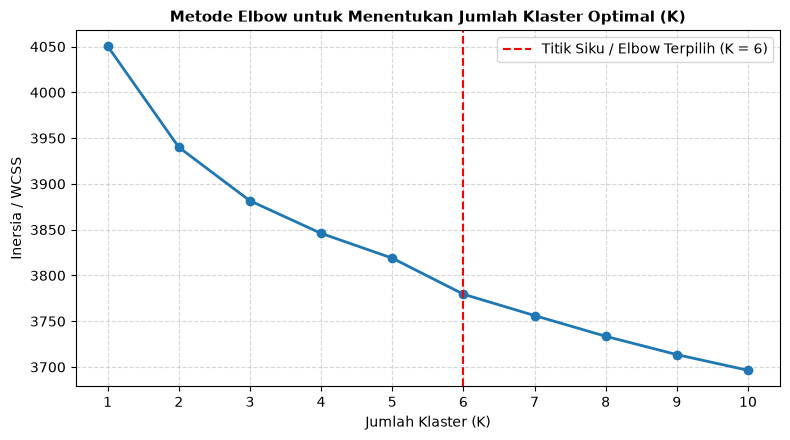

In [4]:
# Penentuan Jumlah Klaster Optimal dengan Metode Elbow
from sklearn.cluster import KMeans

wcss = []
K = range(1, 11)
for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=5)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 4.5))
plt.plot(K, wcss, marker='o', color='#1f77b4', linewidth=2, markersize=6)
plt.title('Metode Elbow untuk Menentukan Jumlah Klaster Optimal (K)', fontsize=11, fontweight='bold')
plt.xlabel('Jumlah Klaster (K)')
plt.ylabel('Inersia / WCSS')
plt.xticks(list(K))
plt.axvline(x=6, color='red', linestyle='--', label='Titik Siku / Elbow Terpilih (K = 6)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


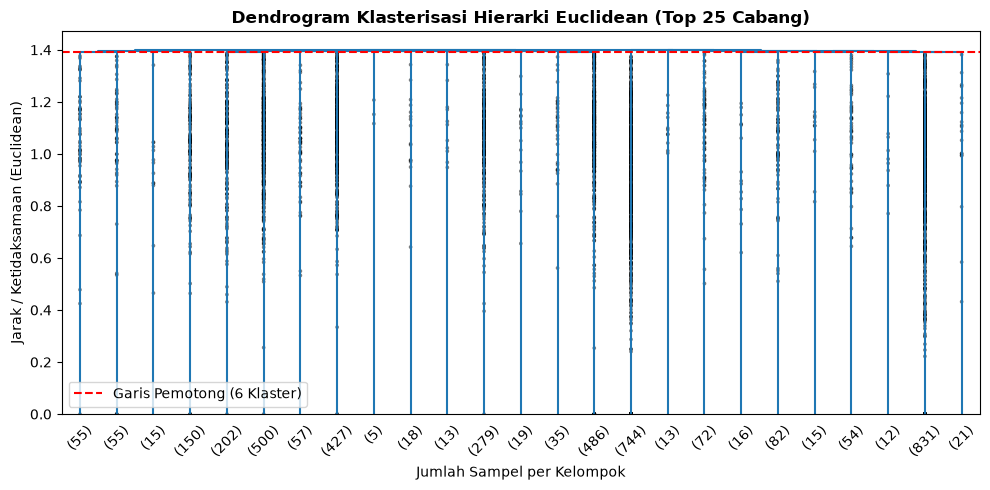

In [5]:
# Visualisasi Dendrogram Hierarki (Euclidean)
Z = linkage(X_dense, method='average', metric='euclidean')

plt.figure(figsize=(10, 5))
plt.title('Dendrogram Klasterisasi Hierarki Euclidean (Top 25 Cabang)', fontsize=12, fontweight='bold')
plt.xlabel('Jumlah Sampel per Kelompok')
plt.ylabel('Jarak / Ketidaksamaan (Euclidean)')
dendrogram(Z, truncate_mode='lastp', p=25, leaf_rotation=45, leaf_font_size=10, show_contracted=True)
plt.axhline(y=1.39, color='r', linestyle='--', label='Garis Pemotong (6 Klaster)')
plt.legend()
plt.tight_layout()
plt.show()


In [6]:
# Mulai pelacakan memori & waktu
tracemalloc.start()
waktu_mulai = time.time()

agg = AgglomerativeClustering(n_clusters=6, metric='euclidean', linkage='average')
df['hierarchical_euclidean'] = agg.fit_predict(X_dense)

waktu_selesai = time.time()
mem_sekarang, mem_puncak = tracemalloc.get_traced_memory()
tracemalloc.stop()

labels = df['hierarchical_euclidean']
hasil_jumlah_klaster = len(set(labels)) - (1 if -1 in labels else 0)
jumlah_noise = (labels == -1).sum()

hasil_waktu = waktu_selesai - waktu_mulai
hasil_memori_mb = mem_puncak / (1024 * 1024)

if hasil_jumlah_klaster > 1:
    hasil_silhouette = metrics.silhouette_score(X_dense, labels, metric='euclidean')
    hasil_dbi = metrics.davies_bouldin_score(X_dense, labels)
else:
    hasil_silhouette = 0.0
    hasil_dbi = 0.0

print("=" * 45)
print("HASIL PENGUJIAN: HIERARCHICAL CLUSTERING EUCLIDEAN")
print("=" * 45)
print(f"1. Jumlah Klaster   : {hasil_jumlah_klaster} klaster (dan {jumlah_noise} data noise)")
print(f"2. Waktu Eksekusi    : {hasil_waktu:.4f} detik")
print(f"3. Silhouette Score : {hasil_silhouette:.4f} (metrik euclidean)")
print(f"4. Penggunaan Memori: {hasil_memori_mb:.2f} MB")
print(f"5. Davies-Bouldin   : {hasil_dbi:.4f} (semakin mendekati 0 semakin baik)")
print("=" * 45)


HASIL PENGUJIAN: HIERARCHICAL CLUSTERING EUCLIDEAN
1. Jumlah Klaster   : 6 klaster (dan 0 data noise)
2. Waktu Eksekusi    : 3.9376 detik
3. Silhouette Score : 0.0166 (metrik euclidean)
4. Penggunaan Memori: 74.83 MB
5. Davies-Bouldin   : 7.1504 (semakin mendekati 0 semakin baik)


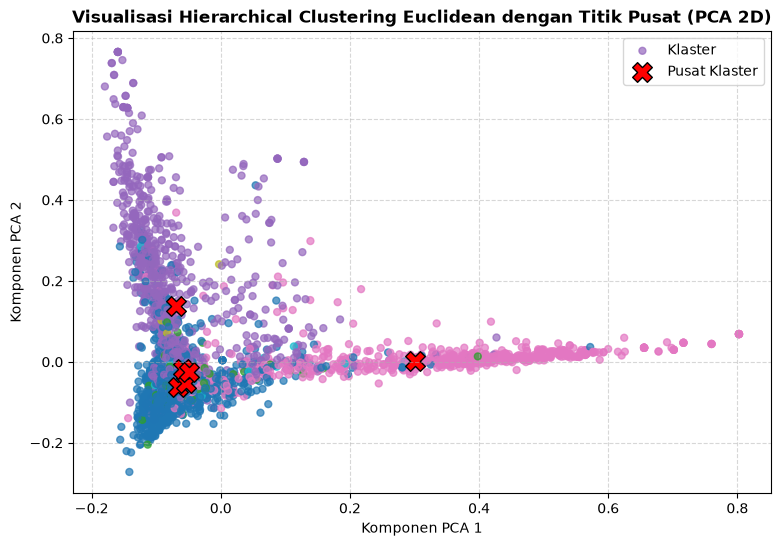

In [7]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_dense)

df['pca1'] = X_pca[:, 0]
df['pca2'] = X_pca[:, 1]

plt.figure(figsize=(9, 6))

non_noise = df[df['hierarchical_euclidean'] != -1]
plt.scatter(
    non_noise['pca1'],
    non_noise['pca2'],
    c=non_noise['hierarchical_euclidean'],
    cmap='tab10',
    s=25,
    alpha=0.7,
    label='Klaster',
)

for i, c in enumerate(sorted(non_noise['hierarchical_euclidean'].unique())):
    pusat_x = non_noise[non_noise['hierarchical_euclidean'] == c]['pca1'].mean()
    pusat_y = non_noise[non_noise['hierarchical_euclidean'] == c]['pca2'].mean()
    plt.scatter(
        pusat_x,
        pusat_y,
        marker='X',
        s=200,
        color='red',
        edgecolors='black',
        label='Pusat Klaster' if i == 0 else '',
    )

plt.title('Visualisasi Hierarchical Clustering Euclidean dengan Titik Pusat (PCA 2D)', fontsize=12, fontweight='bold')
plt.xlabel('Komponen PCA 1')
plt.ylabel('Komponen PCA 2')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


In [8]:
terms = tfidf.get_feature_names_out()
unique_clusters = sorted(df['hierarchical_euclidean'].unique())

print("Kata Kunci Dominan Tiap Klaster Hierarchical Clustering Euclidean:")
for c in unique_clusters:
    if c == -1:
        nama = "NOISE / OUTLIER"
    else:
        nama = f"Klaster {c}"
    
    idx = df[df['hierarchical_euclidean'] == c].index
    mean_tfidf = np.asarray(X_dense[idx].mean(axis=0)).flatten()
    top_terms = [terms[i] for i in mean_tfidf.argsort()[::-1][:7]]
    print(f"[{nama}] ({len(idx)} data): {', '.join(top_terms)}")


Kata Kunci Dominan Tiap Klaster Hierarchical Clustering Euclidean:
[Klaster 0] (2041 data): hoaks, di, video, presiden, prabowo, indonesia, dan
[Klaster 1] (275 data): vaksin, hoaks, dan, bisa, 19, covid, yang
[Klaster 2] (1031 data): tautan, hoaks, pendaftaran, lowongan, kerja, bank, undian
[Klaster 3] (744 data): akun, mengatasnamakan, whatsapp, hoaks, kabupaten, bupati, kota
[Klaster 4] (13 data): thr, budi, hoaks, terkait, pembagian, pemerintah, membahas
[Klaster 5] (72 data): pajak, meninggal, hoaks, akan, april, 2025, pada
